# Class Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_Lab1
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [ ]:
def download_input_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

  return img_gray

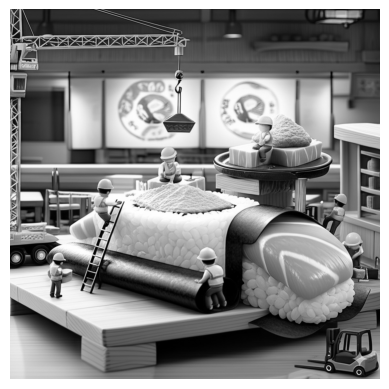

In [ ]:
file_id = '1WRLpWrhsJgguvdAdFNcdGZdc_3NrTmjq'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'
img_gray = download_input_data(download_url)

plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.show()

# Question 1 (30pts)
1.1. Display the histogram and print the basic properties of the given image, including below:
- Shape, width, and height.
- Max, min, average, standard derivation of the pixel values.

1.2. Create an inversed version of the input image. Redo (1.1), then display the output and its histogram.

1.3. Create a new image by changing the grayscale level in the right half from 256 to 32 and and the other to 8. Redo (1.1), then Display the picture and its histogram.

Image Properties:
-----------------
Shape: (1024, 1024)
Width: 1024
Height: 1024
Max pixel value: 255
Min pixel value: 0
Average pixel value: 122.51031970977783
Standard deviation: 73.16191443719717


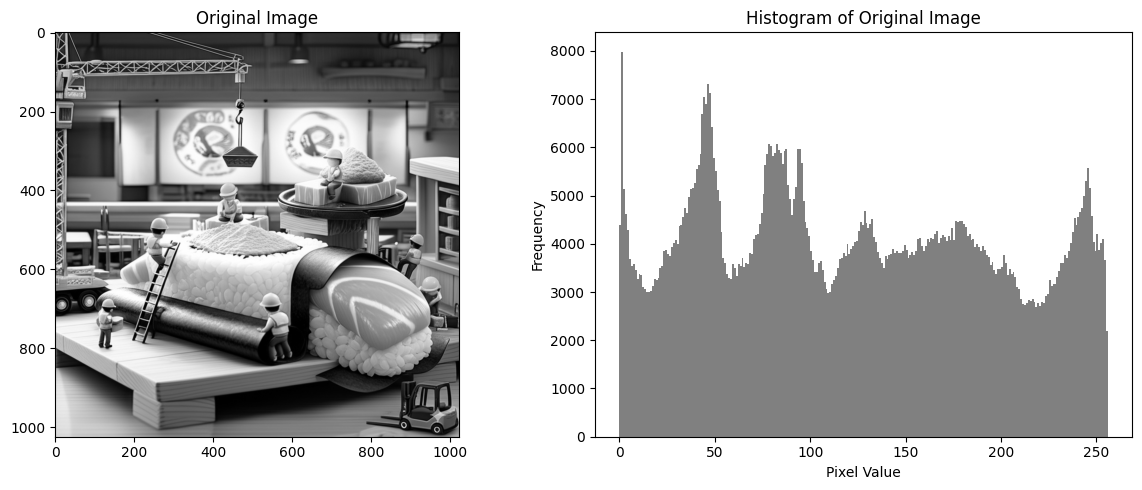

In [ ]:
# 1.1. Display histogram and print basic properties:

# Get image properties
height, width = img_gray.shape

print("Image Properties:")
print("-----------------")
print("Shape:", img_gray.shape)
print("Width:", width)
print("Height:", height)
print("Max pixel value:", np.max(img_gray))
print("Min pixel value:", np.min(img_gray))
print("Average pixel value:", np.mean(img_gray))
print("Standard deviation:", np.std(img_gray))

# Display image
plt.figure(figsize=(12,5))

# Original image
plt.subplot(1,2,1)
plt.imshow(img_gray, cmap='gray')
plt.title("Original Image")
plt.axis('on')

# Histogram
plt.subplot(1,2,2)
plt.hist(img_gray.ravel(), bins=256, range=(0,256), color='gray')
plt.title("Histogram of Original Image")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Inverse Image Properties:
-------------------------
Shape: (1024, 1024)
Width: 1024
Height: 1024
Max pixel value: 255
Min pixel value: 0
Average pixel value: 132.48968029022217
Standard deviation: 73.16191443719717


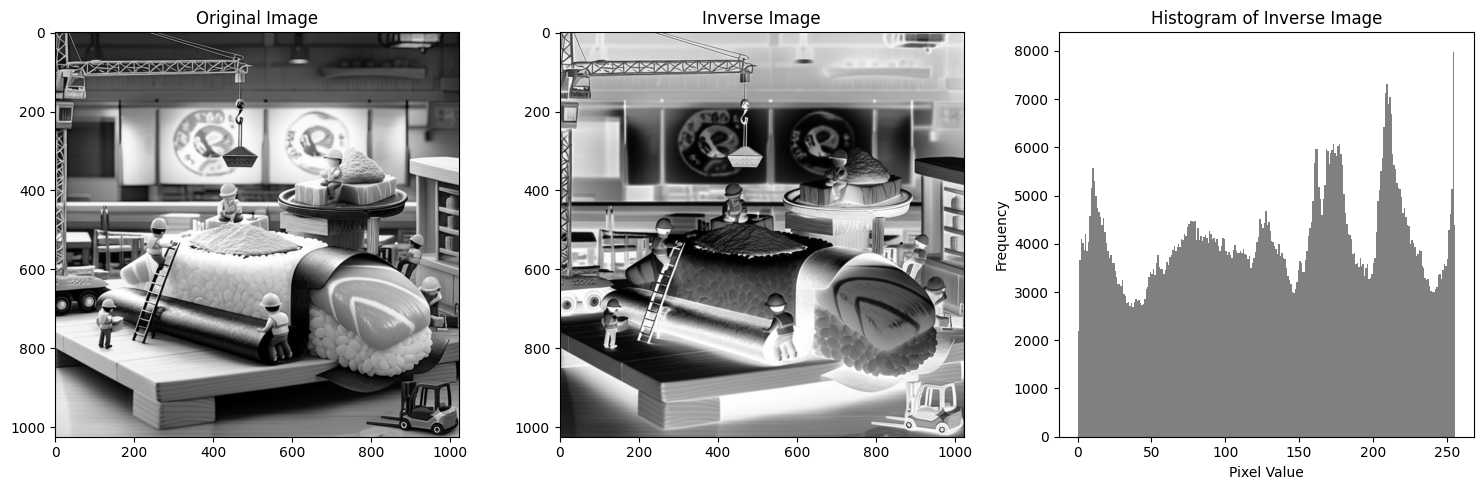

In [ ]:
# 1.2. Create an inversed version of the input image. Redo (1.1), then display the output and its histogram:

# Inverse image
img_inverse = 255 - img_gray

# Get properties
height, width = img_inverse.shape

print("Inverse Image Properties:")
print("-------------------------")
print("Shape:", img_inverse.shape)
print("Width:", width)
print("Height:", height)
print("Max pixel value:", np.max(img_inverse))
print("Min pixel value:", np.min(img_inverse))
print("Average pixel value:", np.mean(img_inverse))
print("Standard deviation:", np.std(img_inverse))

# Display image
plt.figure(figsize=(15,5))

# Original image
plt.subplot(1,3,1)
plt.imshow(img_gray, cmap='gray')
plt.title("Original Image")
plt.axis('on')

# Inversed image
plt.subplot(1,3,2)
plt.imshow(img_inverse, cmap='gray')
plt.title("Inverse Image")
plt.axis('on')

# Histogram
plt.subplot(1,3,3)
plt.hist(img_inverse.ravel(), bins=256, range=(0,256), color='gray')
plt.title("Histogram of Inverse Image")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

New Image Properties:
---------------------
Shape: (1024, 1024)
Width: 1024
Height: 1024
Max pixel value: 248
Min pixel value: 0
Average pixel value: 112.94840240478516
Standard deviation: 72.4297393799544


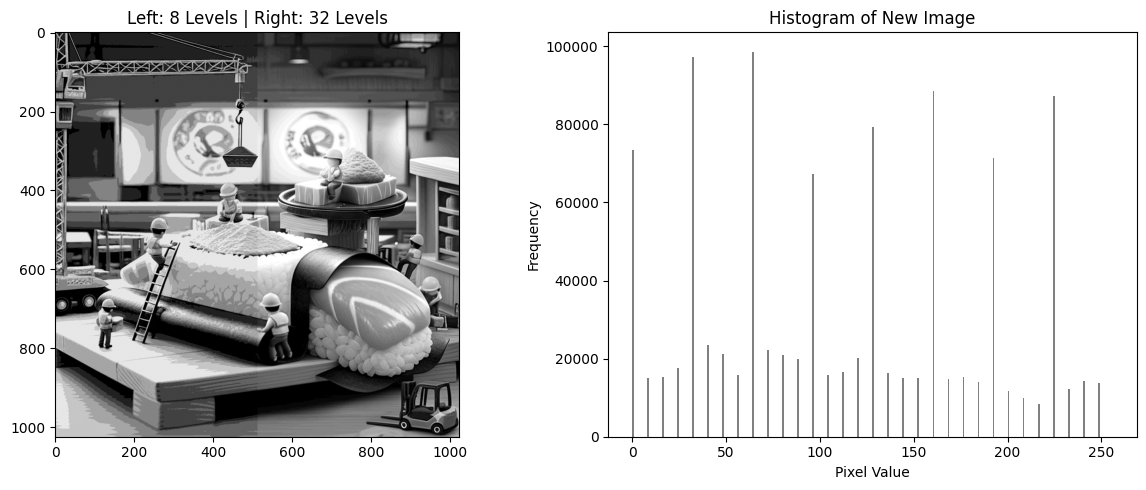

In [ ]:
# 1.3. Create a new image by changing the grayscale level in the right half from 256 to 32 and and the other to 8. Redo (1.1), then Display the picture and its histogram:

height, width = img_gray.shape

img_gray_levels = np.copy(img_gray)

# Divide image into 2 halves
half_width = width // 2

# Left half: 8 grayscale levels
img_gray_levels[:, :half_width] = (img_gray_levels[:, :half_width] // 32) * 32

# Right half: 32 grayscale levels
img_gray_levels[:, half_width:] = (img_gray_levels[:, half_width:] // 8) * 8

# Get properties
print("New Image Properties:")
print("---------------------")
print("Shape:", img_gray_levels.shape)
print("Width:", width)
print("Height:", height)
print("Max pixel value:", np.max(img_gray_levels))
print("Min pixel value:", np.min(img_gray_levels))
print("Average pixel value:", np.mean(img_gray_levels))
print("Standard deviation:", np.std(img_gray_levels))

# Display image
plt.figure(figsize=(12,5))

# Change grayscale image
plt.subplot(1,2,1)
plt.imshow(img_gray_levels, cmap='gray')
plt.title("Left: 8 Levels | Right: 32 Levels")
plt.axis('on')

# Histogram
plt.subplot(1,2,2)
plt.hist(img_gray_levels.ravel(), bins=256, range=(0,256), color='gray')
plt.title("Histogram of New Image")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Question 2 (15pts)
2.1. Determine a random 256x256-block from the input image, then Highlight it by increasing its contrast significantly. Display the output image and its histogram.

2.2. Concatenate the input image and the image (2.1). Display the result.

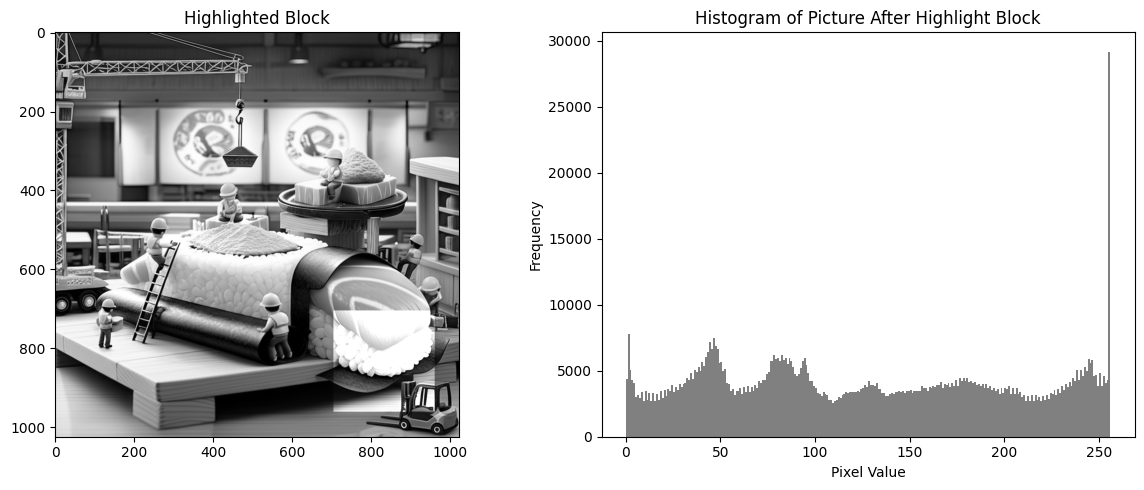

In [ ]:
# 2.1. Determine a random 256x256-block from the input image, then Highlight it by increasing its contrast significantly. Display the output image and its histogram:

img_q2 = np.copy(img_gray)

x = width - 320
y = height - 320

# Extract 256x256 block
block = img_q2[y:y+256, x:x+256]

# Increase contrast
highlight_block = cv.convertScaleAbs(block, alpha=2.0, beta=0)

# Put highlighted block back
img_q2[y:y+256, x:x+256] = highlight_block

# Display image and histogram
plt.figure(figsize=(12,5))

# Output image
plt.subplot(1,2,1)
plt.imshow(img_q2, cmap='gray')
plt.title("Highlighted Block")
plt.axis('on')

# Histogram
plt.subplot(1,2,2)
plt.hist(img_q2.ravel(), bins=256, range=(0,256), color='gray')
plt.title("Histogram of Picture After Highlight Block")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

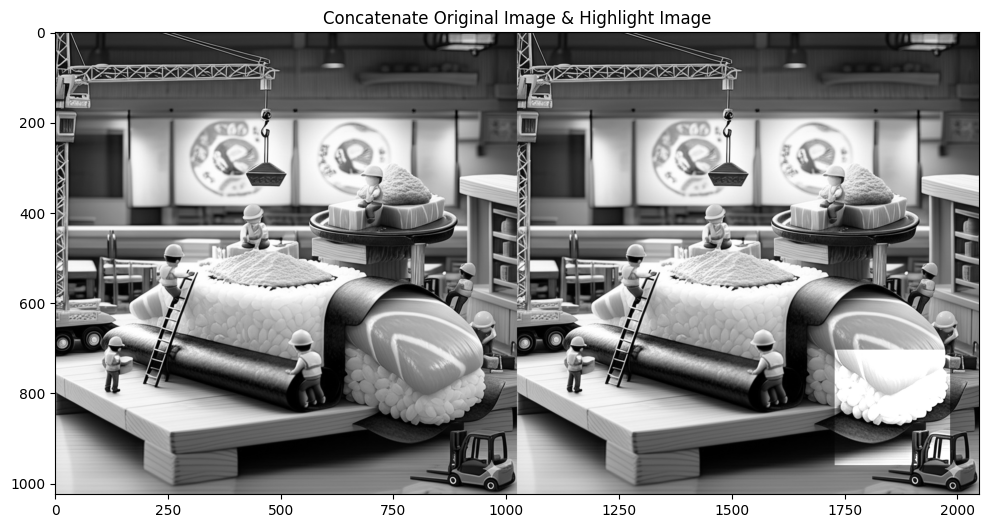

In [ ]:
# 2.2. Concatenate the input image and the image (2.1). Display the result:

concat_img = np.hstack((img_gray, img_q2))

# Display result
plt.figure(figsize=(12,6))
plt.imshow(concat_img, cmap='gray')
plt.title("Concatenate Original Image & Highlight Image")
plt.axis('on')
plt.show()

# Question 3 (55pts)
3.1. Reproduce `lab1_question3_1.jpg` based on the input image. Display the output and the absolute differences between it and the `lab1_question3_1.jpg`.

Note, you can start with the top left quarter of the input image.

3.2. Reproduce `lab1_question3_2.jpg` using the input image. Display the output image and its absolute difference map compared to the target.
Note: An exact match is not required.

3.3. Reproduce `lab1_question3_3.jpg` using the input image. Display the output image and its absolute difference map compared to the target.
Note: An exact match is not required.

3.4. Write your name into the image (3.2) or (3.3) with black color and white border. Display the result.

In [ ]:
# download link for `lab1_question3_1.jpg`, `lab1_question3_2.jpg` and `lab1_question3_3.jpg`
img_31_url = "https://drive.google.com/uc?export=download&id=1DuFlWsU-IXTSpwLUfSwKsd-ia7wVNsVh"
img_32_url = "https://drive.google.com/uc?export=download&id=1LuezxJ3RzGPrNRBdqUoDykAfcwk3nvgR"
img_33_url = "https://drive.google.com/uc?export=download&id=1T5qeJaTi7_myoB717mXxB-NQX9n4bgNf"

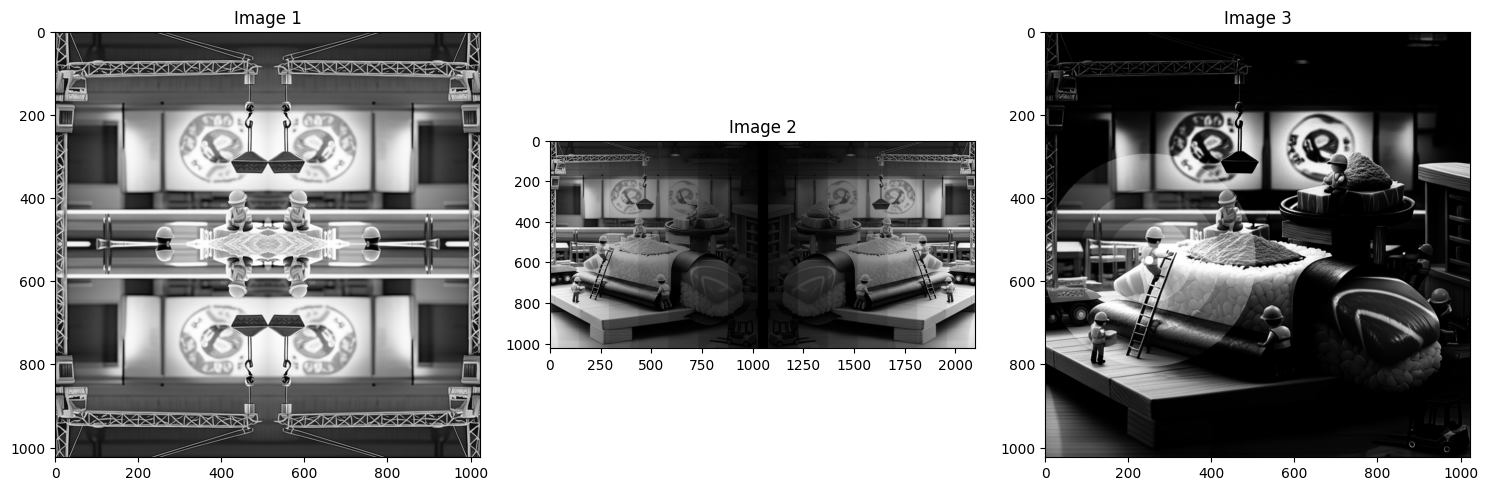

In [ ]:
# Download and display 3 images

# Download images
img_31 = download_input_data(img_31_url)
img_32 = download_input_data(img_32_url)
img_33 = download_input_data(img_33_url)

# Display images
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(img_31, cmap='gray')
plt.title("Image 1")
plt.axis('on')

plt.subplot(1,3,2)
plt.imshow(img_32, cmap='gray')
plt.title("Image 2")
plt.axis('on')

plt.subplot(1,3,3)
plt.imshow(img_33, cmap='gray')
plt.title("Image 3")
plt.axis('on')

plt.tight_layout()
plt.show()

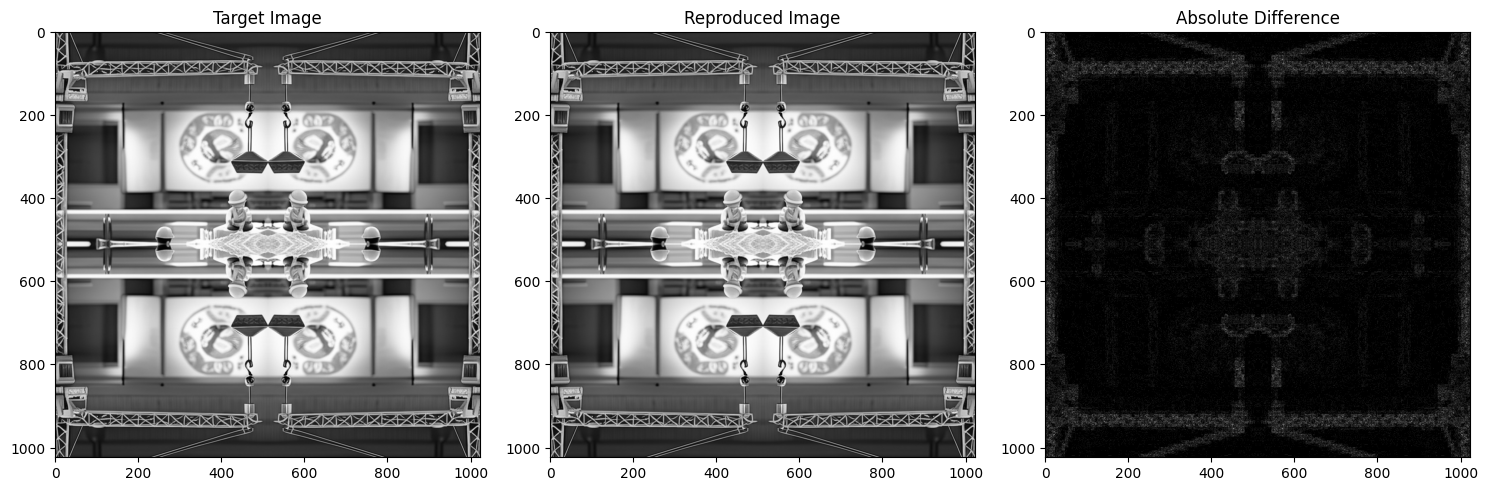

In [ ]:
# 3.1. Reproduce lab1_question3_1.jpg

h, w = img_gray.shape

# Take top-left quarter
quarter = img_gray[:h//2, :w//2]

flip_h = cv.flip(quarter, 1)
flip_v = cv.flip(quarter, 0)
flip_hv = cv.flip(quarter, -1)

top = np.hstack((quarter, flip_h))
bottom = np.hstack((flip_v, flip_hv))

img_q31 = np.vstack((top, bottom))
img_q31 = cv.resize(img_q31, (img_31.shape[1], img_31.shape[0]))
diff_q31 = cv.absdiff(img_31, img_q31)

# Display results
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(img_31, cmap='gray')
plt.title("Target Image")
plt.axis('on')

plt.subplot(1,3,2)
plt.imshow(img_q31, cmap='gray')
plt.title("Reproduced Image")
plt.axis('on')

plt.subplot(1,3,3)
plt.imshow(diff_q31, cmap='gray')
plt.title("Absolute Difference")
plt.axis('on')

plt.tight_layout()
plt.show()

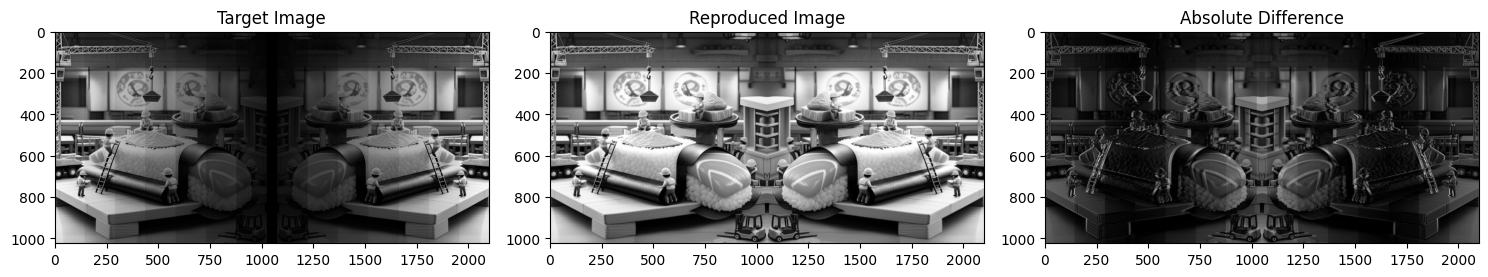

In [ ]:
# 3.2. Reproduce lab1_question3_2.jpg.

small_img = cv.resize(img_gray, (w//2, h//2))

left = small_img
right = cv.flip(small_img, 1)

img_q32 = np.hstack((left, right))
img_q32 = cv.convertScaleAbs(img_q32, alpha=0.6, beta=0)
img_q32 = cv.resize(img_q32, (img_32.shape[1], img_32.shape[0]))
diff_q32 = cv.absdiff(img_32, img_q32)

# Display results
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(img_32, cmap='gray')
plt.title("Target Image")
plt.axis('on')

plt.subplot(1,3,2)
plt.imshow(img_q32, cmap='gray')
plt.title("Reproduced Image")
plt.axis('on')

plt.subplot(1,3,3)
plt.imshow(diff_q32, cmap='gray')
plt.title("Absolute Difference")
plt.axis('on')

plt.tight_layout()
plt.show()

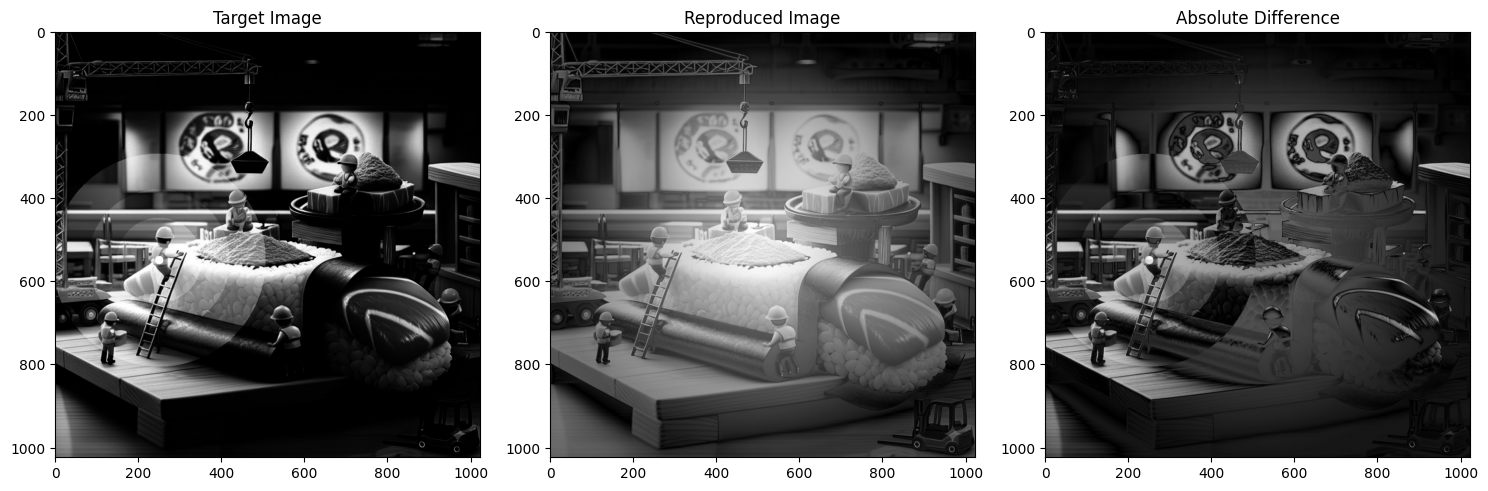

In [ ]:
# 3.3. Reproduce lab1_question3_3.jpg.

img_q33 = cv.convertScaleAbs(img_gray, alpha=0.45, beta=-20)

mask = np.zeros_like(img_q33, dtype=np.uint8)

center_x = w // 2
center_y = h // 2

for y in range(h):
    for x in range(w):
        distance = np.sqrt((x-center_x)**2 + (y-center_y)**2)
        intensity = 255 - distance * 0.5
        intensity = np.clip(intensity, 0, 255)
        mask[y, x] = intensity

img_q33 = cv.addWeighted(img_q33, 0.7, mask, 0.3, 0)
img_q33 = cv.resize(img_q33, (img_33.shape[1], img_33.shape[0]))
diff_q33 = cv.absdiff(img_33, img_q33)

# Display results
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(img_33, cmap='gray')
plt.title("Target Image")
plt.axis('on')

plt.subplot(1,3,2)
plt.imshow(img_q33, cmap='gray')
plt.title("Reproduced Image")
plt.axis('on')

plt.subplot(1,3,3)
plt.imshow(diff_q33, cmap='gray')
plt.title("Absolute Difference")
plt.axis('on')

plt.tight_layout()
plt.show()

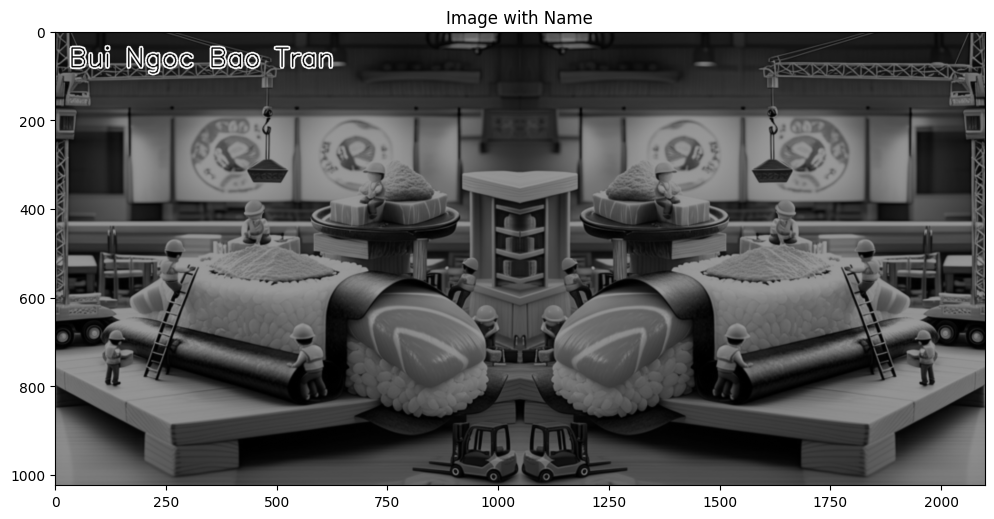

In [ ]:
# 3.4. Write your name into image (3.2) with black color and white border.

img_name = img_q32.copy()

# White border
cv.putText(img_name, "Bui Ngoc Bao Tran", (30, 80), cv.FONT_HERSHEY_SIMPLEX, 2, 255, 9)

# Black text
cv.putText(img_name, "Bui Ngoc Bao Tran", (30, 80), cv.FONT_HERSHEY_SIMPLEX, 2, 0, 2)

# Display result
plt.figure(figsize=(12,12))
plt.imshow(img_name, cmap='gray')
plt.title("Image with Name")
plt.axis('on')
plt.show()